# ResNet vs. Plain Deep CNN vs. Shallow CNN on EuroSAT

| Model | What it is |
|---|---|
| `simple_cnn` | A small, shallow 4-layer CNN (the "normal CNN" baseline) |
| `plain50` | The exact ResNet-50 layout, but with the skip connections **removed** |
| `resnet50` | ResNet-50 with bottleneck blocks  |


In [1]:
import time
import json

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("Warning: no GPU found. ResNet-50 will be very slow on CPU.")

Using device: cuda


## 1. Settings

In [ ]:
EPOCHS = 15
BATCH_SIZE = 128
LR = 2e-3
NUM_WORKERS = 0         
DATA_DIR = "./data"
MODELS_TO_RUN = ["simple_cnn", "plain50", "resnet50"]

torch.manual_seed(0)

## 2. The models

### The bottleneck block
One block = **1x1 conv (squeeze) -> 3x3 conv (work) -> 1x1 conv (expand)**, then add the input back (`out + identity`).


In [ ]:
class Bottleneck(nn.Module):
    """1x1 (squeeze) -> 3x3 (work) -> 1x1 (expand), plus an optional skip connection."""

    expansion = 4

    def __init__(self, in_channels, mid_channels, stride=1, use_skip=True):
        super().__init__()
        out_channels = mid_channels * self.expansion
        self.use_skip = use_skip

        self.conv1 = nn.Conv2d(in_channels, mid_channels, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        self.conv2 = nn.Conv2d(mid_channels, mid_channels, 3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(mid_channels)
        self.conv3 = nn.Conv2d(mid_channels, out_channels, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.downsample = None
        if use_skip and (stride != 1 or in_channels != out_channels):
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))  # no ReLU yet

        if self.use_skip:
            identity = x if self.downsample is None else self.downsample(x)
            out = out + identity  #idea of ResNet

        return self.relu(out)

### The full network
A stem, then 4 stages of blocks (`layers = (3, 4, 6, 3)` is ResNet-50), then average pooling and a linear classifier.



In [4]:
class ResNet(nn.Module):
    """ResNet-50-style network. Set use_skip=False to get the 'plain' version."""

    def __init__(self, layers=(3, 4, 6, 3), num_classes=10, use_skip=True):
        super().__init__()
        self.in_channels = 64

        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        self.layer1 = self._make_layer(layers[0], 64, stride=1, use_skip=use_skip)
        self.layer2 = self._make_layer(layers[1], 128, stride=2, use_skip=use_skip)
        self.layer3 = self._make_layer(layers[2], 256, stride=2, use_skip=use_skip)
        self.layer4 = self._make_layer(layers[3], 512, stride=2, use_skip=use_skip)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512 * Bottleneck.expansion, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def _make_layer(self, num_blocks, mid_channels, stride, use_skip):
        blocks = [Bottleneck(self.in_channels, mid_channels, stride, use_skip)]
        self.in_channels = mid_channels * Bottleneck.expansion
        for _ in range(num_blocks - 1):
            blocks.append(Bottleneck(self.in_channels, mid_channels, 1, use_skip))
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        return self.fc(torch.flatten(x, 1))

### Shallow baseline CNN

In [5]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class SimpleCNN(nn.Module):
    """A normal, shallow CNN: 4 conv layers."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn_relu(3, 32), nn.MaxPool2d(2),     # 64 -> 32
            conv_bn_relu(32, 64), nn.MaxPool2d(2),    # 32 -> 16
            conv_bn_relu(64, 128), nn.MaxPool2d(2),   # 16 -> 8
            conv_bn_relu(128, 256), nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))


def build_model(name, num_classes=10):
    if name == "simple_cnn":
        return SimpleCNN(num_classes)
    if name == "plain50":
        return ResNet(use_skip=False, num_classes=num_classes)
    if name == "resnet50":
        return ResNet(use_skip=True, num_classes=num_classes)
    raise ValueError(f"Unknown model: {name}")

### Sanity check


In [6]:
for name in ["simple_cnn", "plain50", "resnet50"]:
    m = build_model(name)
    out = m(torch.randn(2, 3, 64, 64))
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{name:<11} output shape: {tuple(out.shape)} | params: {n_params / 1e6:.2f}M")

simple_cnn  output shape: (2, 10) | params: 0.39M
plain50     output shape: (2, 10) | params: 20.74M
resnet50    output shape: (2, 10) | params: 23.52M


## 3. Data
EuroSAT 

In [7]:
MEAN = (0.3444, 0.3803, 0.4078)
STD = (0.2037, 0.1366, 0.1148)

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_full = datasets.EuroSAT(DATA_DIR, transform=train_tf, download=True)
eval_full = datasets.EuroSAT(DATA_DIR, transform=eval_tf, download=False)

g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(train_full), generator=g).tolist()
n_train = int(0.8 * len(perm))
train_set = Subset(train_full, perm[:n_train])
val_set = Subset(eval_full, perm[n_train:])

pin = torch.cuda.is_available()
train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                          pin_memory=pin, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_set, BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=pin, persistent_workers=NUM_WORKERS > 0)

classes = train_full.classes
print("Classes:", classes)
print(f"Train images: {len(train_set)} | Val images: {len(val_set)}")

100.0%


Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Train images: 21600 | Val images: 5400


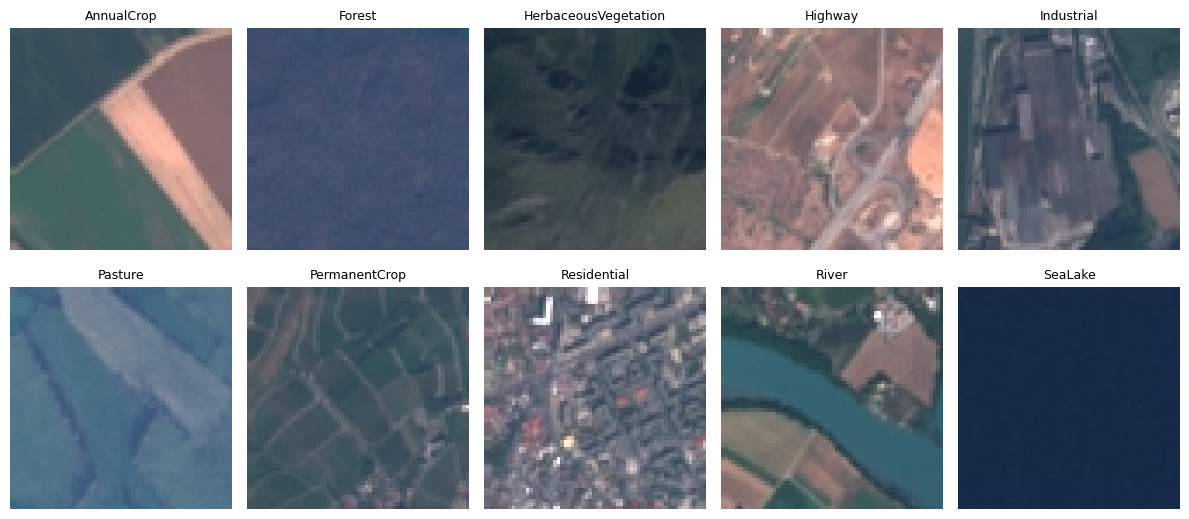

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
shown = {}
for idx in perm:
    img, label = eval_full[idx]
    if label not in shown:
        shown[label] = img
    if len(shown) == len(classes):
        break

for ax, (label, img) in zip(axes.flat, sorted(shown.items())):
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)  # undo normalize
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Training code


In [9]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None, use_amp=False):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)

            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            count += y.size(0)

    return total_loss / count, correct / count


def train_model(name, epochs=EPOCHS, lr=LR):
    model = build_model(name).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n=== {name} | {n_params / 1e6:.2f}M parameters ===")

    use_amp = device.type == "cuda"
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler, use_amp)
        va_loss, va_acc = run_epoch(model, val_loader, criterion, use_amp=use_amp)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch:2d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
              f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - start:5.0f}s")

    result = {
        "params_millions": n_params / 1e6,
        "train_seconds": time.time() - start,
        "final_val_acc": history["val_acc"][-1],
        "best_val_acc": max(history["val_acc"]),
        "history": history,
    }
    return model, result

## 5. Train all models


In [10]:
results = {}
trained_models = {}

for name in MODELS_TO_RUN:
    model, res = train_model(name)
    results[name] = res
    trained_models[name] = model


=== simple_cnn | 0.39M parameters ===
epoch  1/15 | train loss 1.140 acc 0.640 | val loss 0.755 acc 0.770 |   101s
epoch  2/15 | train loss 0.651 acc 0.784 | val loss 0.596 acc 0.784 |   109s
epoch  3/15 | train loss 0.527 acc 0.819 | val loss 0.735 acc 0.746 |   117s
epoch  4/15 | train loss 0.461 acc 0.839 | val loss 0.657 acc 0.785 |   124s
epoch  5/15 | train loss 0.387 acc 0.867 | val loss 0.398 acc 0.865 |   131s
epoch  6/15 | train loss 0.333 acc 0.885 | val loss 0.608 acc 0.781 |   139s
epoch  7/15 | train loss 0.272 acc 0.905 | val loss 1.695 acc 0.692 |   146s
epoch  8/15 | train loss 0.259 acc 0.909 | val loss 0.330 acc 0.890 |   154s
epoch  9/15 | train loss 0.225 acc 0.922 | val loss 0.976 acc 0.807 |   161s
epoch 10/15 | train loss 0.201 acc 0.931 | val loss 0.189 acc 0.933 |   169s
epoch 11/15 | train loss 0.173 acc 0.940 | val loss 0.222 acc 0.923 |   176s
epoch 12/15 | train loss 0.151 acc 0.950 | val loss 0.149 acc 0.950 |   184s
epoch 13/15 | train loss 0.132 acc 0.

d:\Road\PyTorch\.venv\lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch  1/15 | train loss 1.876 acc 0.287 | val loss 1.838 acc 0.324 |    20s
epoch  2/15 | train loss 1.447 acc 0.444 | val loss 1.308 acc 0.538 |    40s
epoch  3/15 | train loss 1.145 acc 0.593 | val loss 1.004 acc 0.662 |    60s
epoch  4/15 | train loss 0.957 acc 0.671 | val loss 1.291 acc 0.657 |    80s
epoch  5/15 | train loss 0.868 acc 0.705 | val loss 0.860 acc 0.708 |   100s
epoch  6/15 | train loss 0.797 acc 0.730 | val loss 0.926 acc 0.678 |   120s
epoch  7/15 | train loss 0.719 acc 0.760 | val loss 0.662 acc 0.774 |   141s
epoch  8/15 | train loss 0.636 acc 0.788 | val loss 0.602 acc 0.811 |   161s
epoch  9/15 | train loss 0.557 acc 0.815 | val loss 0.552 acc 0.818 |   180s
epoch 10/15 | train loss 0.491 acc 0.838 | val loss 0.469 acc 0.843 |   201s
epoch 11/15 | train loss 0.441 acc 0.855 | val loss 0.406 acc 0.862 |   221s
epoch 12/15 | train loss 0.396 acc 0.869 | val loss 0.346 acc 0.888 |   241s
epoch 13/15 | train loss 0.352 acc 0.884 | val loss 0.314 acc 0.898 |   261s

## 6. Results

In [11]:
print(f"{'model':<12}{'params (M)':>12}{'best val acc':>15}{'final val acc':>15}{'time (s)':>11}")
for name, r in results.items():
    print(f"{name:<12}{r['params_millions']:>12.2f}{r['best_val_acc']:>15.4f}"
          f"{r['final_val_acc']:>15.4f}{r['train_seconds']:>11.0f}")

model         params (M)   best val acc  final val acc   time (s)
simple_cnn          0.39         0.9596         0.9596        206
plain50            20.74         0.9030         0.9026        302
resnet50           23.52         0.9674         0.9674        364


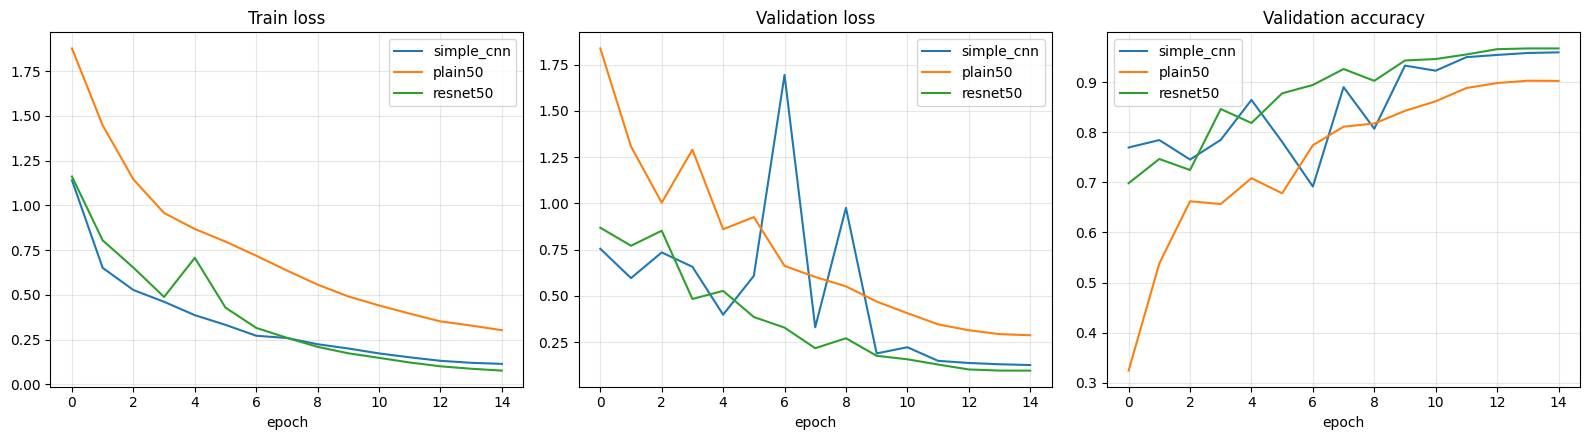

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, r in results.items():
    h = r["history"]
    axes[0].plot(h["train_loss"], label=name)
    axes[1].plot(h["val_loss"], label=name)
    axes[2].plot(h["val_acc"], label=name)

for ax, title in zip(axes, ["Train loss", "Validation loss", "Validation accuracy"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("results.png", dpi=130)
plt.show()

with open("results.json", "w") as f:
    json.dump(results, f, indent=2)

## 7. Which classes get confused?
A confusion matrix for the best model shows where it still makes mistakes (e.g. river vs. highway).

Best model: resnet50


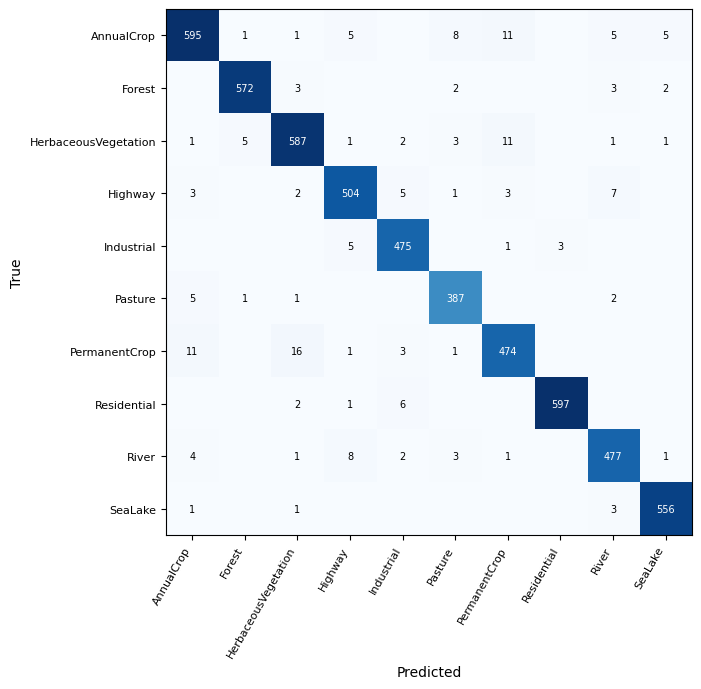

In [13]:
best_name = max(results, key=lambda n: results[n]["final_val_acc"])
model = trained_models[best_name]
model.eval()

n_cls = len(classes)
conf = torch.zeros(n_cls, n_cls, dtype=torch.int64)
with torch.no_grad():
    for x, y in val_loader:
        preds = model(x.to(device)).argmax(1).cpu()
        for t, p in zip(y, preds):
            conf[t, p] += 1

print("Best model:", best_name)
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.imshow(conf, cmap="Blues")
ax.set_xticks(range(n_cls)); ax.set_xticklabels(classes, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(n_cls)); ax.set_yticklabels(classes, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(n_cls):
    for j in range(n_cls):
        v = conf[i, j].item()
        if v > 0:
            ax.text(j, i, v, ha="center", va="center", fontsize=7,
                    color="white" if v > conf.max() / 2 else "black")
plt.tight_layout()
plt.show()